# Qué quiebra un chancador y qué sale de él: la curva de energía t10, la función de aparición y la curva de clasificación

**Pregunta:** ¿Cómo fija la energía aplicada a una roca la finura de sus fragmentos, y qué tamaños elige quebrar un chancador de cono con una abertura dada?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** los notebooks 01 y 02 del tema 02-size-distributions
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este notebook usted puede:

- calcular la energía específica que aplica un apriete y convertirla en el índice de finura t10 del ensayo de caída de peso JKMRC;
- dibujar la función de aparición que dice cómo se reparte entre tamaños más finos la masa de una partícula quebrada, y leer la familia t de ella;
- dibujar la curva de clasificación que dice qué tamaños toma un apriete y cuáles pasan de largo;
- decir cómo mueven cada curva la abertura de la máquina y la competencia del mineral.

## Preparación

Numpy y matplotlib, como en todo el conjunto.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

La celda importa directamente los módulos de quiebre y de clasificación del motor, una función por idea de este notebook, y la tabla de carreras de diseño por máquina.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.crusher.breakage import specific_energy, t10_of, phi_from_t10, appearance_cum, t_family
from pipeline.model.crusher.classification import classification_params, classify
from pipeline.model.crusher.machines import REF_THROW_MM
from pipeline.model.crusher import Operating, evaluate
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

El punto de operación del caso de referencia S01 (un cono secundario, CSS 32 mm, 360 rpm, mineral con A*b = 55). Propietario: este repositorio, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Clase de licencia: MIT; los artefactos versionados los escribe el pipeline a partir de los parámetros de cada caso. Archivo leído: `data/derived/manifests/S01.json`, bloque `params`.

La celda lee el punto de operación y el F80 de alimentación que el motor calcula para él.

In [2]:
# Lea el punto de operación de S01 y el F80 que el motor calcula para su alimentación
manifest = json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))
op = Operating(**manifest["params"])
f80 = evaluate(op).f80
print(op.machine, "CSS", op.css_mm, "mm,", op.speed_rpm, "rpm, A*b", op.ore_axb, "| F80", round(f80, 2), "mm")

cone-sec CSS 32.0 mm, 360.0 rpm, A*b 55.0 | F80 126.03 mm


## Método

**Paso 1, la energía de un apriete.** Un chancador quiebra la roca apretándola. El motor resume el apriete como una energía específica de conminución por apriete, en kWh por tonelada, que crece con la carrera de diseño de la máquina y con su velocidad: $E_{cs} = 0{,}033\,T_{ref}\,(\mathrm{rpm}/350)$, donde $T_{ref}$ es la carrera de diseño del tipo de máquina (30 mm en un cono secundario). Esta relación es propia del motor, fijada en `breakage.py`: no se invoca fuente publicada para su constante 0,033, y las relaciones publicadas de la cadena parten en el paso siguiente. El control de carrera en vivo no interviene aquí: más carrera engrosa el producto a través de la clasificación, no de la energía. La celda evalúa la energía de S01 y la de cada tipo de máquina en su propio punto de diseño.

In [3]:
# Energía específica por apriete de S01, y de cada tipo de máquina a 350 rpm
ecs = specific_energy(op.speed_rpm, REF_THROW_MM[op.machine])
print(f"S01: Ecs = {ecs:.4f} kWh/t")
for machine, throw in REF_THROW_MM.items():
    print(f"{machine:16s} carrera de diseño {throw:3d} mm -> Ecs = {specific_energy(350, throw):.3f} kWh/t")

S01: Ecs = 1.0183 kWh/t
cone-sec         carrera de diseño  30 mm -> Ecs = 0.990 kWh/t
cone-tert        carrera de diseño  16 mm -> Ecs = 0.528 kWh/t
cone-short-head  carrera de diseño  16 mm -> Ecs = 0.528 kWh/t
gyratory         carrera de diseño  30 mm -> Ecs = 0.990 kWh/t
jaw              carrera de diseño  38 mm -> Ecs = 1.254 kWh/t


**Paso 2, de la energía a la finura.** El ensayo de caída de peso JKMRC mide qué tan fino se quiebra una roca con una energía dada, con el índice $t_{10}$, la fracción de los fragmentos más finos que una décima parte del tamaño de la partícula madre. Su relación energía-finura es $t_{10} = A\,(1 - e^{-b E_{cs}})$ (Napier-Munn et al., 1996; https://search.worldcat.org/title/37081193), donde $A$ es la finura límite y $b$ la rapidez con que el mineral se acerca a ella. Solo el producto $A b$ importa para ordenar minerales: un valor bajo es un mineral duro. El motor fija $A = 60$ por ciento, limita $t_{10}$ a 0,44 para que la función de aparición de abajo pueda representarlo, y toma $b = A b / A$. La figura dibuja $t_{10}$ contra la energía para un mineral duro (A*b = 30), uno medio (55, el de S01) y uno blando (110) y marca el punto de operación de S01.

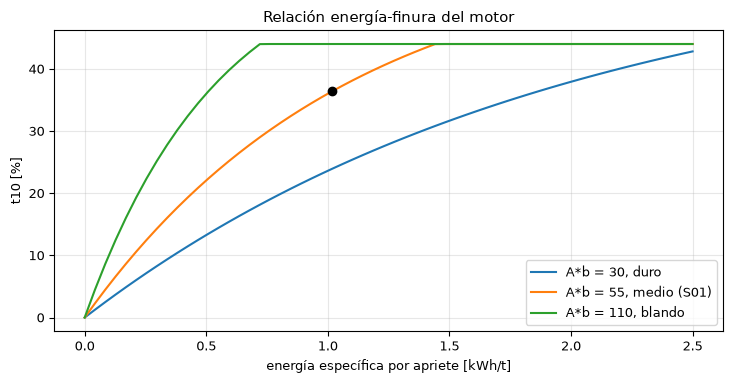

t10 de S01 = 0.3641


In [4]:
# Grafique t10 contra la energía específica para un mineral duro, uno medio y uno blando y marque S01
energy = np.linspace(0, 2.5, 60)
fig, ax = plt.subplots()
for axb, name in ((30, "duro"), (55, "medio (S01)"), (110, "blando")):
    ax.plot(energy, [t10_of(e, axb) * 100 for e in energy], label=f"A*b = {axb}, {name}")
ax.plot([ecs], [t10_of(ecs, op.ore_axb) * 100], "ko")
ax.set_xlabel("energía específica por apriete [kWh/t]")
ax.set_ylabel("t10 [%]")
ax.set_title("Relación energía-finura del motor")
ax.legend()
fig.tight_layout()
plt.show()
print(f"t10 de S01 = {t10_of(ecs, op.ore_axb):.4f}")

Las curvas suben con fuerza y luego se aplanan, porque cada unidad extra de energía compra menos finura, y se aplanan en el tope de 44 por ciento, que el mineral blando alcanza antes de 1 kWh/t. El punto de S01 queda sobre la curva media en t10 = 36,4 por ciento. La figura no muestra la forma de los tamaños de los fragmentos, solo el número t10; el paso siguiente convierte ese número en una distribución completa.

**Paso 3, la función de aparición.** Para una madre de tamaño $y$ la fracción acumulada de fragmentos más finos que $x$ sigue la forma de Austin, con $u = x/y$:

$$B(u) = \varphi\,u^{\gamma} + (1 - \varphi)\,u^{\beta}, \qquad \gamma = 0{,}35,\ \beta = 4{,}2$$

(Austin, Klimpel y Luckie, 1984, como los cita el módulo del motor; la fuente del producto para la familia es Napier-Munn et al., 1996). El peso $\varphi$ se resuelve para que la curva pase por $t_{10}$ en $u = 1/10$. La familia t de JKMRC, $t_n$ para la fracción más fina que $y/n$, se lee de la misma curva. La celda resuelve $\varphi$ para los tres minerales con la energía de S01 e imprime $t_2$ a $t_{75}$ de S01.

In [5]:
# Resuelva el peso de aparición de los tres minerales con la energía de S01 e imprima la familia t de S01
phis = {axb: phi_from_t10(t10_of(ecs, axb)) for axb in (30, 55, 110)}
for axb, phi in phis.items():
    print(f"A*b = {axb:3d}: t10 = {t10_of(ecs, axb):.3f}, phi = {phi:.3f}")
for k, tn in t_family(t10_of(ecs, op.ore_axb)):
    print(f"t{k:<3d} = {tn:.3f}")

A*b =  30: t10 = 0.239, phi = 0.536
A*b =  55: t10 = 0.364, phi = 0.815
A*b = 110: t10 = 0.440, phi = 0.980
t2   = 0.650
t4   = 0.502
t10  = 0.364
t25  = 0.264
t50  = 0.207
t75  = 0.180


La figura dibuja la función de aparición de los tres minerales en ejes logarítmicos, con la familia t de S01 como puntos. En $u = 0{,}1$ cada curva pasa por su $t_{10}$, y las tres curvas se separan a ambos lados: el mineral duro conserva más de su masa en fragmentos gruesos (bajo a la izquierda), el blando produce más finos.

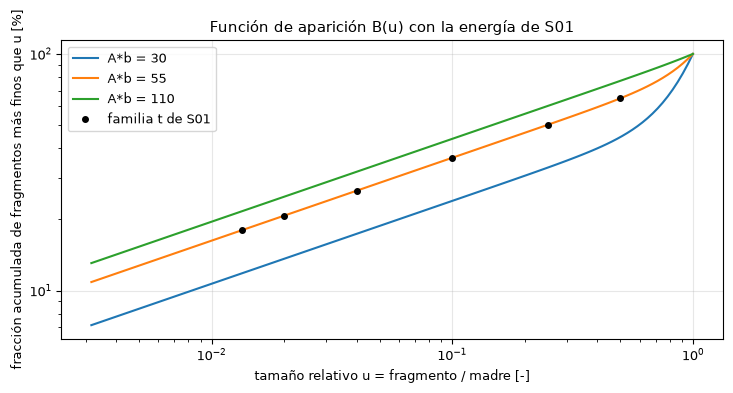

In [6]:
# Grafique la función de aparición acumulada de los tres minerales y la familia t de S01
u = np.logspace(-2.5, 0, 120)
fig, ax = plt.subplots()
for axb, phi in phis.items():
    ax.plot(u, [appearance_cum(v, phi) * 100 for v in u], label=f"A*b = {axb}")
family = t_family(t10_of(ecs, op.ore_axb))
ax.plot([1 / k for k, _ in family], [tn * 100 for _, tn in family], "ko", ms=4, label="familia t de S01")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("tamaño relativo u = fragmento / madre [-]")
ax.set_ylabel("fracción acumulada de fragmentos más finos que u [%]")
ax.set_title("Función de aparición B(u) con la energía de S01")
ax.legend()
fig.tight_layout()
plt.show()

La figura muestra que un solo número, t10, fija toda la forma: la familia t se lee de la misma curva en $u = 1/n$, de modo que los puntos de S01 caen sobre ella por construcción, y lo que muestran es que un solo número, t10, fija t2 a t75 sin otro parámetro. No muestra adónde van los fragmentos en la malla de tamices, que depende del tamaño de la madre; esa contabilidad es la matriz de quiebre del notebook siguiente. Sigue el segundo ingrediente, la clasificación.

**Paso 4, la curva de clasificación.** No toda partícula que entra a la cámara es atrapada: las pequeñas caen por la abertura, las grandes no caben. La función de clasificación $C(d)$ es la probabilidad de que una partícula de tamaño $d$ sea atrapada y quebrada en lugar de pasar de largo (Whiten, 1972; https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf), en la forma K1, K2, K3 de Andersen y Napier-Munn (1988; https://www.semanticscholar.org/paper/Power-prediction-for-cone-crushers-Andersen-Napier-Munn/2c60e81b909b65cba85b44583354dc8e310ec2f8):

$$C(d) = \begin{cases} 0 & d \le K_1 \\ 1 - \left(\dfrac{K_2 - d}{K_2 - K_1}\right)^{K_3} & K_1 < d < K_2 \\ 1 & d \ge K_2 \end{cases}$$

$K_1$ crece con la abertura de lado cerrado, y $K_2$ sigue la abertura de lado abierto, de modo que más carrera deja escapar partículas mayores (Evertsson, 1999; https://doi.org/10.1016/S0892-6875(99)00136-3). La celda pide al motor las tres constantes con la abertura de S01 y con una cerrada y una abierta.

In [7]:
# K1, K2, K3 con la abertura de S01, una 15 % más cerrada y una 15 % más ancha
settings = {"cerrada": op.css_mm * 0.85, "S01": op.css_mm, "abierta": op.css_mm * 1.15}
constants = {}
for name, css in settings.items():
    constants[name] = classification_params(op.machine, css, f80_mm=f80, calibrated=False, throw_mm=op.throw_mm)
for name, k in constants.items():
    print(f"{name:7s} CSS = {settings[name]:5.2f} mm  K1 = {k.k1:6.2f}  K2 = {k.k2:6.2f}  K3 = {k.k3}")

cerrada CSS = 27.20 mm  K1 =  24.68  K2 =  59.04  K3 = 2.3
S01     CSS = 32.00 mm  K1 =  29.00  K2 =  68.40  K3 = 2.3
abierta CSS = 36.80 mm  K1 =  33.32  K2 =  77.76  K3 = 2.3


La figura dibuja C(d) para las tres aberturas en un eje de tamaños logarítmico.

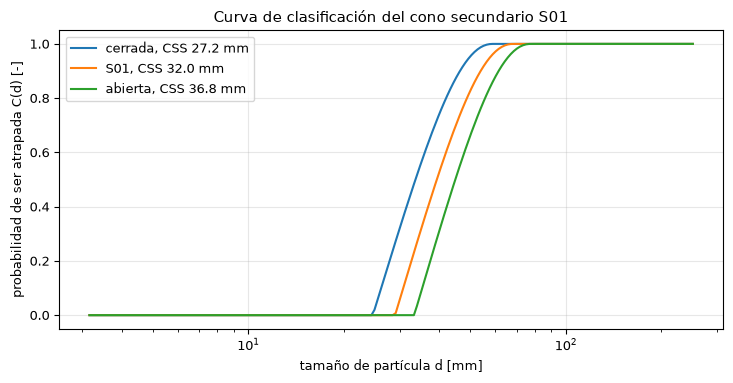

In [8]:
# Grafique C(d) para las tres aberturas contra el tamaño de partícula
sizes = np.logspace(0.5, 2.4, 200)
fig, ax = plt.subplots()
for name, k in constants.items():
    ax.plot(sizes, [classify(d, k) for d in sizes], label=f"{name}, CSS {settings[name]:.1f} mm")
ax.set_xscale("log")
ax.set_xlabel("tamaño de partícula d [mm]")
ax.set_ylabel("probabilidad de ser atrapada C(d) [-]")
ax.set_title("Curva de clasificación del cono secundario S01")
ax.legend()
fig.tight_layout()
plt.show()

Cada curva es cero hasta su K1 y uno desde su K2, y toda la forma de S se desplaza a la derecha al abrir la abertura: con la propia abertura de S01 las partículas bajo 29 mm nunca son atrapadas y las sobre 68,4 mm siempre lo son. Entre esos tamaños el material se separa por azar, por eso el producto de un chancador siempre contiene algo de sobretamaño respecto de la abertura. La figura muestra la selección, pero no lo que el chancador hace con una partícula elegida (eso es la función de aparición) ni cómo se arma el producto cuando los fragmentos pueden ser atrapados de nuevo; eso es el cálculo de Whiten del notebook siguiente.

## Resultados

**Respuesta:** en S01 un apriete aplica 1,0183 kWh/t, lo que da t10 = 0,3641 para el mineral con A*b = 55 y un peso de aparición phi = 0,815, de modo que t2 a t75 van de 0,650 a 0,180. Un mineral más duro (A*b = 30) obtiene t10 = 0,239 con la misma energía y uno más blando (110) llega al tope de 0,44. Respecto de la abertura, el chancador elige sus partículas por tamaño: K1 = 29,00 mm, K2 = 68,40 mm y K3 = 2,3 con la abertura de 32 mm de S01, así que las partículas bajo 29 mm pasan sin quebrarse y las sobre 68,4 mm son siempre atrapadas.

La primera figura muestra la finura saturándose con la energía, la segunda la familia de un parámetro de los tamaños de fragmento, la tercera la selección deslizándose hacia tamaños mayores al abrir la abertura. Un validador concluiría que el lado de quiebre del motor es una cadena de tres relaciones publicadas con pocos números libres, y que la abertura actúa sobre la selección mientras el mineral actúa sobre la fragmentación: cerrar el chancador selecciona partículas más pequeñas, un mineral más duro se quiebra en fragmentos más gruesos. Ninguna de las tres curvas dice aún cómo se ve el producto; para eso hay que combinarlas, como en el notebook 02.

## Resumen

La energía por apriete fija el índice de finura t10 a través del A*b del mineral, t10 fija la función de aparición, y la abertura fija qué tamaños se seleccionan. Son los dos ingredientes del modelo del chancador: una función de selección C y una función de quiebre B. El notebook 02 los combina en el balance poblacional que Whiten escribió para un chancador y lo resuelve paso a paso.

## Referencias

- Whiten, W. J. (1972), The simulation of crushing plants with models developed using multiple spline regression, Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193
- Andersen, J. S., Napier-Munn, T. J. (1988), Power prediction for cone crushers, Proc. 3rd Mill Operators' Conference, AusIMM, 103-109. https://www.semanticscholar.org/paper/Power-prediction-for-cone-crushers-Andersen-Napier-Munn/2c60e81b909b65cba85b44583354dc8e310ec2f8
- Evertsson, C. M. (1999), Modelling of flow in cone crushers, Minerals Engineering 12(12), 1479-1499. https://doi.org/10.1016/S0892-6875(99)00136-3
- Austin, L. G., Klimpel, R. R., Luckie, P. T. (1984), Process Engineering of Size Reduction: Ball Milling, SME-AIME, New York. https://search.worldcat.org/title/11603131